## This Notebook compares ANUGA model outputs to SWOT HR products

In [11]:
import os
import sys
import anuga
import glob
import h5netcdf
import xarray as xr
import rioxarray as rxr
import pandas as pd
import geopandas as gpd
# import contextily as cx
import numpy as np
import matplotlib.pyplot as plt
import hvplot.xarray
import zipfile
import rasterio

from rasterio.enums import Resampling
from rasterio.mask import mask
from pyproj import CRS
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from anuga.file.netcdf import NetCDFFile
from netCDF4 import Dataset
from anuga.utilities.plot_utils import Make_Geotif
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr, pearsonr
import cartopy.crs as ccrs
import cartopy.feature as cfeature


from pathlib import Path
import matplotlib as mpl
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.gridspec as gridspec

### Import datasets

In [12]:
#work folder
# work_folder = '/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/MODEL_folder'
work_folder = Path('/Users/alchrist/Documents/Interns/Kica/Notebook Folders')
#water mask
# water_mask_shp = "/Users/skica/Desktop/2025_Summer_Research/FINAL_PRESENTATION_FIGURES/water_mask_utm.geojson"
water_mask_shp = work_folder / "komo_water_connected_10.shp"
water_mask=gpd.read_file(water_mask_shp) #change water mask

#model .sww file
# model_path = ('/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/MODEL_folder/'
              # 'gabon_237cms_20230409093100-118023_Meshes_base_10000m2_BoutBrBrBr_full_add33cm_20250715.sww') #change model
model_path = work_folder / 'gabon_237cms_20230409093100-8583_Meshes_base_10000m2_BoutBrBrBr_full_add33cm_longer_20250708.sww'

#swot file
### For now I change change each swot file in comparison to the model timestep
# swot_path = ('/Users/skica/Desktop/2025_Summer_Research/SWOTRaster Products Komo Estuary April 10 - 17, 220250610025002/swot_raster_cal_val_all/'
#                 'SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_497_016_077F_20230421T073812_20230421T073833_PGC0_01.nc') #change swot file
# tide_wl_path = ('/Users/skica/Desktop/2025_Summer_Research/SWOTRaster Products Komo Estuary April 10 - 17, 220250610025002/'
#                'tpxo_4_10-4_20_2023.csv')

# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_485_016_077F_20230409T093037_20230409T093058_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_486_016_077F_20230410T092115_20230410T092136_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_487_016_077F_20230411T091153_20230411T091214_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_488_016_077F_20230412T090231_20230412T090252_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_489_016_077F_20230413T085309_20230413T085330_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_490_016_077F_20230414T084347_20230414T084408_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_491_016_077F_20230415T083425_20230415T083446_PGC0_02.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_492_016_077F_20230416T082503_20230416T082524_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_493_016_077F_20230417T081541_20230417T081602_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_494_016_077F_20230418T080619_20230418T080640_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_495_016_077F_20230419T075657_20230419T075718_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_495_016_077F_20230419T075657_20230419T075718_PGC0_02.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_496_016_077F_20230420T074735_20230420T074756_PGC0_01.nc
# SWOT_L2_HR_Raster_100m_UTM32N_N_x_x_x_497_016_077F_20230421T073812_20230421T073833_PGC0_01.nc

### Explore model file

In [13]:
#Explore model metadata
sww = Dataset(model_path, mode='r')
for attr in sww.ncattrs():
    print(f"{attr}: {getattr(sww, attr)}")

# Check available dimensions and variables
print("\nDimensions:", sww.dimensions.keys())
print("\nVariables:", sww.variables.keys())
#sww.close()

institution: Geosciences Australia
description: merged:Output from anuga.file.sww suitable for plotting
smoothing: Yes
vertices_are_stored_uniquely: False
order: 2
revision_number: b533cb128b798f8bdb4b854e0ab132aaff985e36
revision_date: 2023-06-01 17:25:15+10:00
anuga_version: 3.2.0dev
starttime: 0
timezone: UTC
xllcorner: 0.0
yllcorner: 0.0
zone: 32232
hemisphere: undefined
false_easting: 500000
false_northing: 10000000
datum: wgs84
projection: UTM
units: m

Dimensions: dict_keys(['number_of_volumes', 'number_of_triangle_vertices', 'number_of_vertices', 'numbers_in_range', 'number_of_points', 'number_of_timesteps'])

Variables: dict_keys(['x', 'y', 'volumes', 'friction', 'friction_range', 'elevation', 'elevation_range', 'elevation_c', 'friction_c', 'xmomentum', 'xmomentum_range', 'ymomentum', 'ymomentum_range', 'stage', 'stage_range', 'ymomentum_c', 'stage_c', 'xmomentum_c', 'time'])


In [14]:
#Explore available time steps
time_values = sww.variables['time'][:]
model_timestep = 118#288
print(f'Number of time steps: {len(time_values)}')
print(f'Timestamp values: {time_values}') # Use Notebook: Compute_timesteps to find the matching timestep with SWOT
print(f'Timestamp values: {time_values[model_timestep]}')

Number of time steps: 119
Timestamp values: [     0. 100100. 103675. 107250. 110825. 114400. 117975. 121550. 125125.
 128700. 132275. 135850. 139425. 143000. 146575. 150150. 153725. 157300.
 160875. 164450. 168025. 171600. 175175. 178750. 182325. 185900. 189475.
 193050. 196625. 200200. 203775. 207350. 210925. 214500. 218075. 221650.
 225225. 228800. 232375. 235950. 239525. 243100. 246675. 250250. 253825.
 257400. 260975. 264550. 268125. 271700. 275275. 278850. 282425. 286000.
 289575. 293150. 296725. 300300. 303875. 307450. 311025. 314600. 318175.
 321750. 325325. 328900. 332475. 336050. 339625. 343200. 346775. 350350.
 353925. 357500. 361075. 364650. 368225. 371800. 375375. 378950. 382525.
 386100. 389675. 393250. 396825. 400400. 403975. 407550. 411125. 414700.
 418275. 421850. 425425. 429000. 432575. 436150. 439725. 443300. 446875.
 450450. 454025. 457600. 461175. 464750. 468325. 471900. 475475. 479050.
 482625. 486200. 489775. 493350. 496925. 500500. 504075. 507650. 511225.
 514800

In [28]:
pd.Timestamp(str(model_path).split('/')[-1].split('_')[2][:14])

Timestamp('2023-04-09 09:31:00')

In [39]:
#Start time
start_time = pd.Timestamp(str(model_path).split('/')[-1].split('_')[2][:14])


# Compute corresponding times
times = [start_time + pd.to_timedelta(ts, unit='s') for ts in time_values]
# times = pd.to_datetime(times).strftime('%Y%m%d%H%M%S')
# Format nicely
count = 0
for ts, t in zip(time_values, times):
    count += 1
    print(f"Timestep: '{count}' {int(ts)} → {t}")


Timestep: '1' 0 → 2023-04-09 09:31:00
Timestep: '2' 100100 → 2023-04-10 13:19:20
Timestep: '3' 103675 → 2023-04-10 14:18:55
Timestep: '4' 107250 → 2023-04-10 15:18:30
Timestep: '5' 110825 → 2023-04-10 16:18:05
Timestep: '6' 114400 → 2023-04-10 17:17:40
Timestep: '7' 117975 → 2023-04-10 18:17:15
Timestep: '8' 121550 → 2023-04-10 19:16:50
Timestep: '9' 125125 → 2023-04-10 20:16:25
Timestep: '10' 128700 → 2023-04-10 21:16:00
Timestep: '11' 132275 → 2023-04-10 22:15:35
Timestep: '12' 135850 → 2023-04-10 23:15:10
Timestep: '13' 139425 → 2023-04-11 00:14:45
Timestep: '14' 143000 → 2023-04-11 01:14:20
Timestep: '15' 146575 → 2023-04-11 02:13:55
Timestep: '16' 150150 → 2023-04-11 03:13:30
Timestep: '17' 153725 → 2023-04-11 04:13:05
Timestep: '18' 157300 → 2023-04-11 05:12:40
Timestep: '19' 160875 → 2023-04-11 06:12:15
Timestep: '20' 164450 → 2023-04-11 07:11:50
Timestep: '21' 168025 → 2023-04-11 08:11:25
Timestep: '22' 171600 → 2023-04-11 09:11:00
Timestep: '23' 175175 → 2023-04-11 10:10:35
Ti

### Extract model timestep and save as geotiff

In [31]:
Make_Geotif(swwFile= str(model_path),  #name+'.sww', 
             output_quantities=['elevation'],
             myTimeStep= [0],
             CellSize=100.0, 
             lower_left=None, upper_right=None,
             EPSG_CODE=32632, 
             proj4string=None,
             velocity_extrapolation=True,
             #min_allowed_height=1.0e-05,
             output_dir=str(work_folder), #'.',
             #bounding_polygon=bounding_polygon,
             #internal_holes=internal_holes,
             verbose=True)

Reading sww File ...
Extracting required data ...
Computing grid of output locations...
Making interpolation functions...
Reduction =  0
output_quantity elevation
Making raster ...


Reading sww File ...
Extracting required data ...
Computing grid of output locations...
Making interpolation functions...
Reduction =  0
output_quantity stage
Making raster ...
Reduction =  1
output_quantity stage
Making raster ...
Reduction =  2
output_quantity stage
Making raster ...
Reduction =  3
output_quantity stage
Making raster ...
Reduction =  4
output_quantity stage
Making raster ...
Reduction =  5
output_quantity stage
Making raster ...
Reduction =  6
output_quantity stage
Making raster ...
Reduction =  7
output_quantity stage
Making raster ...
Reduction =  8
output_quantity stage
Making raster ...
Reduction =  9
output_quantity stage
Making raster ...
Reduction =  10
output_quantity stage
Making raster ...
Reduction =  11
output_quantity stage
Making raster ...
Reduction =  12
output_quantity stage
Making raster ...
Reduction =  13
output_quantity stage
Making raster ...
Reduction =  14
output_quantity stage
Making raster ...
Reduction =  15
output_quantity stage
Making ras

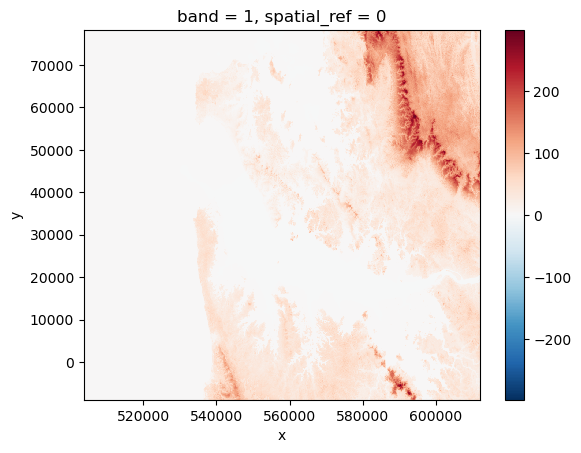

In [33]:
# Extract first polygon and convert to list of [x, y] coords
#polygon_geom = water_mask.geometry.iloc[0]
#bounding_polygon = list(polygon_geom.exterior.coords)
#internal_holes = [list(interior.coords) for interior in polygon_geom.interiors]

Make_Geotif(swwFile= str(model_path),  #name+'.sww', 
             output_quantities=['stage'],
             myTimeStep= 'all',
             CellSize=100.0, 
             lower_left=None, upper_right=None,
             EPSG_CODE=32632, 
             proj4string=None,
             velocity_extrapolation=True,
             #min_allowed_height=1.0e-05,
             output_dir=str(work_folder), #'.',
             #bounding_polygon=bounding_polygon,
             #internal_holes=internal_holes,
             verbose=True)

# Immediately read the model .tif file in output directory
tif_files = glob.glob(os.path.join(work_folder, "*.tif"))
model_tif_path = max(tif_files, key=os.path.getctime)  # latest by creation time

# 3. Load it with rioxarray
model_water1 = rxr.open_rasterio(model_tif_path, masked=True)
model_water1.plot()

In [41]:
timestr = start_time + pd.to_timedelta(time_values[0], unit='s').strftime('%Y%m%d%H%M%S')

AttributeError: 'Timedelta' object has no attribute 'strftime'

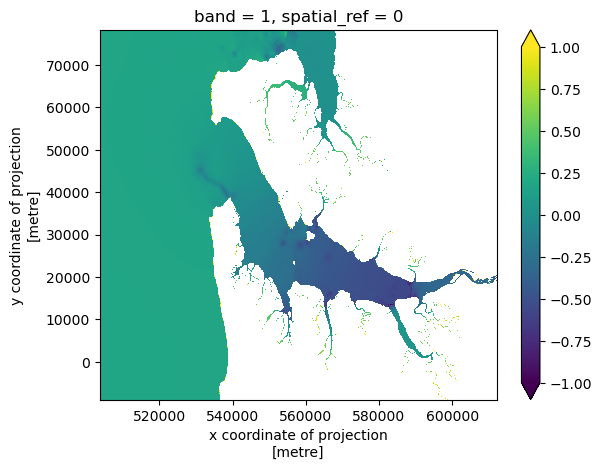

In [20]:
for i in time_values:
    timestr = start_time + pd.to_timedelta(i, unit='s').strftime('%Y%m%d%H%M%S')
    model_water = model_water1.rio.clip(water_mask.geometry.values, water_mask.crs)
model_water.plot(vmin=-1,vmax=1)

### Load, process and prep SWOT data for comparison

In [41]:
#read the swot file
ds_raster = xr.open_dataset(swot_path, engine='h5netcdf')
ds_raster

<xarray.Dataset> Size: 414MB
Dimensions:                  (x: 1453, y: 1453)
Coordinates:
  * x                        (x) float64 12kB 4.861e+05 4.862e+05 ... 6.313e+05
  * y                        (y) float64 12kB -9.3e+03 -9.2e+03 ... 1.359e+05
Data variables: (12/39)
    crs                      object 8B ...
    longitude                (y, x) float64 17MB ...
    latitude                 (y, x) float64 17MB ...
    wse                      (y, x) float32 8MB ...
    wse_qual                 (y, x) float32 8MB ...
    wse_qual_bitwise         (y, x) float64 17MB ...
    ...                       ...
    load_tide_fes            (y, x) float32 8MB ...
    load_tide_got            (y, x) float32 8MB ...
    pole_tide                (y, x) float32 8MB ...
    model_dry_tropo_cor      (y, x) float32 8MB ...
    model_wet_tropo_cor      (y, x) float32 8MB ...
    iono_cor_gim_ka          (y, x) float32 8MB ...
Attributes: (12/49)
    Conventions:                   CF-1.7
    title:                         Level 2 KaRIn High Rate Raster Data Product
    institution:                   JPL
    source:                        Ka-band radar interferometer
    history:                       2024-05-23T06:33:11Z : Creation
    platform:                      SWOT
    ...                            ...
    mgrs_latitude_band:            N
    x_min:                         486100.0
    x_max:                         631300.0
    y_min:                         -9300.0
    y_max:                         135900.0
    product_version:               01

#### Computing bitwise quality_flags (phase_unwrapping, bright_land etc)

In [42]:
quality_variables = {}

for name, variable in ds_raster.variables.items():
    if name.endswith(("qual", "bitwise")):
        quality_variables[name] = None

sorted(list(quality_variables))

variable_name = "water_area"
quality_variable_name = f"{variable_name}_qual_bitwise"

qual = ds_raster.variables[quality_variable_name].copy() 

atts = dict(qual.attrs.copy())
flags = pd.DataFrame({'flag_meanings': atts.get("flag_meanings").split(" "), 
                      'flag_masks': atts.get("flag_masks"), }) \
          .set_index("flag_meanings")

unq_ints_qual = sorted(list(set(qual.load().data.astype(np.int64).flatten().tolist())))

def qual_bits_iter(n):
    while n:
        b = n & (~n+1)
        yield b
        n ^= b

decomposed_qual = {}
for i in sorted(unq_ints_qual):
    if i not in decomposed_qual:
        decomposed_qual[i] = qual_bits_iter(i)
type(decomposed_qual), len(decomposed_qual)

new_columns_qual = {}
for i, j in enumerate(list(set(decomposed_qual))):
    new_columns_qual[j] = flags['flag_masks'] \
        .apply(lambda x: x in [b for b in qual_bits_iter(j)])
lookup = flags.join(pd.DataFrame(new_columns_qual).sort_index(axis=1)).copy()

flags_to_mask = sorted([i for i in lookup.index if i.startswith(('geolocation_qual','low'))])
display(flags_to_mask)

tmp = lookup.copy()  # Make a copy of the table.
del tmp['flag_masks']  # Remove the 'flag_masks' column.
indices = tmp.loc[flags_to_mask].apply(lambda x: x.any()).copy()  # Get a boolean array of integers that comprise the mask.
integers_to_mask = sorted(tmp.columns[indices].astype(np.int64).tolist())  # Get the columns/integers with one or more flag set to True.
print("Unique integers to mask: ",len(integers_to_mask))
#print(integers_to_mask)

['geolocation_qual_degraded',
 'geolocation_qual_suspect',
 'low_coherence_water_suspect']

Unique integers to mask:  170


#### Applying filters

In [43]:
# Apply the cross_track 
c_track_cond = ((ds_raster['cross_track'] > 10000) & (ds_raster['cross_track'] < 60000)) | \
              ((ds_raster['cross_track'] < -10000) & (ds_raster['cross_track'] > -60000))
#Apply number of pixels
n_wse_pix_cond = (ds_raster['n_wse_pix'] > 15)
wse_qual_bit_cond = (ds_raster['wse_qual_bitwise'] == 0)
wse_qual_cond = (ds_raster['wse_qual'] == 0)
wa_qual_bit_cond = (ds_raster['water_area_qual_bitwise']==0)
water_frac_cond = (ds_raster['water_frac']<0.5) #& (ds_raster['water_frac']<1.0001)

# Apply bitwise filtering
bitwise_cond = np.isin(ds_raster['water_area_qual_bitwise'], integers_to_mask)
bad_pixels = bitwise_cond | water_frac_cond
comb_cond = c_track_cond & ~bad_pixels# bitwise_cond#wse_qual_bit_cond & wse_qual_cond & wa_qual_bit_cond & water_frac_cond #& n_wse_pix_cond #& bitwise_cond ### Add the different conditions you want to mask at this point


# bitwise_cond = np.isin(ds_raster[f'{variable_name}_qual_bitwise'], integers_to_mask)
#         bad_pixels = bitwise_cond | water_frac_cond #| dark_frac_cond#| n_wse_pix_cond #| wse_qual_cond
#         comb_cond = c_track_cond & ~bad_pixels 

xs = ds_raster["wse"].where(comb_cond.compute())# & bitwise_cond, drop=True)
# Manually compute bounds of remaining data
x0, x1 = xs.x.min().item(), xs.x.max().item()
y0, y1 = xs.y.min().item(), xs.y.max().item()


xs = xs.rio.write_crs("EPSG:32632")
xs = xs.rio.clip_box(minx=x0, miny=y0, maxx=x1, maxy=y1, crs="EPSG:32632")
xs.rio.to_raster("/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/test21.tif") #test if not geometrically correct

#### Clip SWOT raster to water mask

##### Pass uniform filter to average pixel values

In [44]:
# from scipy.ndimage import uniform_filter

# #ds_raster = xr.open_dataset(swot_path, engine='h5netcdf')
# #xs = ds_raster["wse"].where(comb_cond.compute())
# # Get nodata value and pixel size
# nodata = xs.rio.nodata
# pixel_size = abs(xs.rio.resolution()[0])
# kernel_size = 10  # Or int(1000 / pixel_size)

# # Convert to NumPy array and handle nodata as NaN
# data = xs.values
# mask = (data == nodata)
# data = np.where(mask, np.nan, data)

# # Apply smoothing (filling NaNs temporarily)
# smoothed = uniform_filter(np.nan_to_num(data), size=kernel_size, mode='mirror')

# # Wrap into a new DataArray
# xs1 = xr.DataArray(smoothed,dims=xs.dims,coords=xs.coords,attrs=xs.attrs)

# xs1.rio.write_crs(xs.rio.crs, inplace=True)
# xs1.rio.write_nodata(nodata, inplace=True)

# # Export
# xs1.rio.to_raster("raster_smoothed_1km2_25.tif")

In [45]:
if isinstance(xs, xr.Dataset):
    xs = xs[list(xs.data_vars)[0]]  # Grab first variable
water_mask = water_mask.to_crs(xs.rio.crs) # Reproject vector to raster CRS
xs_clipped = xs.rio.clip(water_mask.geometry, water_mask.crs, drop=True)     # Clip using rioxarray
xs_clipped = xs_clipped.where(xs_clipped != 0, np.nan)  # Replace 0 with NaN if needed
xs_clipped = xs_clipped.rio.write_crs("EPSG:32632")
xs_clipped.rio.to_raster('/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/MODEL_folder/'
                         'swot_wse_water_test3.tif') # Export to GeoTIFF

### Comparing Model to SWOT

#### Checking to see if you have the two prepared datasets in memory

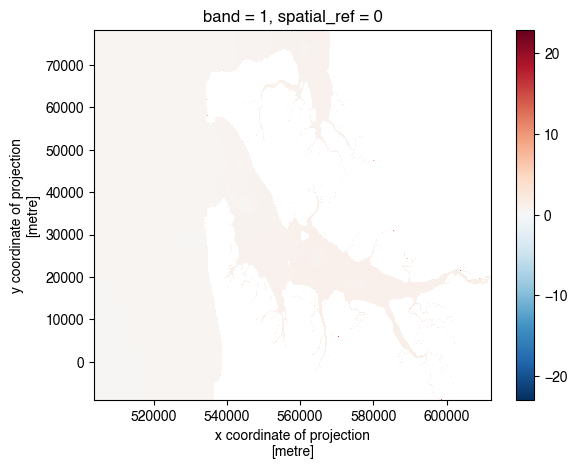

In [46]:
model_water = model_water
model_water.plot()
model_water.rio.to_raster('/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/MODEL_folder/'
                         'anuga_water_test3.tif')

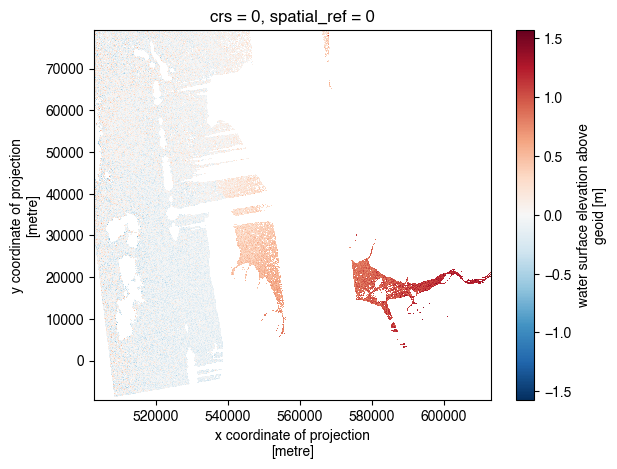

In [47]:
swot_water = xs_clipped
swot_water.plot()


#### Resampling SWOT to model grid

In [48]:
swot_water_resampled = swot_water.rio.reproject_match(model_water, resampling=Resampling.bilinear) # 1 = bilinear interpolation
# model_water, swot_water_resampled = xr.align(model_water, swot_water_resampled)
swot_water_resampled.rio.to_raster('/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/MODEL_folder/'
                         'swot_wse_resampled_test4.tif') # Export to GeoTIFF
#modelRas, swotRas_resampled = xr.align(modelRas, swotRas_resampled)

#### Difference map

In [49]:
diff_map = (swot_water_resampled - model_water)
diff_map.name = 'SWOT - Model'

diff_map_ex = diff_map.transpose("band", "y", "x")
diff_map_ex.rio.to_raster("/Users/skica/Desktop/2025_Summer_Research/FINAL_PRESENTATION_FIGURES/diff_map_rivers.tif")


diff_map.hvplot.image(
    x='x',y='y',
    cmap='BuRd',
    #clim=(-np.abs(diff_map.quantile(0.05)), np.abs(diff_map.quantile(0.95))),
    #width=800, height=400,
    colorbar=True,
    clabel='WSE difference (m) (SWOT - Model)',
    title='Difference map'
)


:DynamicMap   [band]
   :Image   [x,y]   (SWOT - Model)

#### Computing statistics

In [50]:
model_vals = model_water.values.ravel()
swot_vals = swot_water_resampled.values.ravel()
mask = np.isfinite(model_vals) & np.isfinite(swot_vals)
model_clean, swot_clean = model_vals[mask], swot_vals[mask]

sm_compare = pd.DataFrame({'model_wse': model_clean, 'swot_wse': swot_clean}).dropna()
# Check number of valid pixels
print(f'Valid pixels after dropping NaNs: {len(sm_compare)}')

Valid pixels after dropping NaNs: 260343


##### Removing outliers: Comment out if you dont want to remove outliers

In [51]:
# #remove outliers
# Q1 = sm_compare['model_wse'].quantile(0.25)
# Q3 = sm_compare['model_wse'].quantile(0.75)
# IQR = Q3 - Q1
# min_value = Q1 - (1.5*IQR)
# max_value = Q3 + (1.5*IQR)

# Q1s = sm_compare['swot_wse'].quantile(0.25)
# Q3s = sm_compare['swot_wse'].quantile(0.75)
# IQRs = Q3s - Q1s
# min_value_s = Q1s - (1.5*IQRs)
# max_value_s = Q3s + (1.5*IQRs)

# # print(Q1,Q1s)
# # print(Q3, Q3s)
# # print(IQR, IQRs)
# # print(min_value, min_value_s)
# # print(max_value, max_value_s)

# sm_compare = sm_compare[
#     ((sm_compare['model_wse'] > min_value) & (sm_compare['model_wse'] < max_value))  &
#     ((sm_compare['swot_wse'] > min_value_s) & (sm_compare['swot_wse'] < max_value_s))
# ]

# print("Valid pixels after removing outliers: ",len(sm_compare))

In [52]:
model_wse = sm_compare['model_wse']
swot_wse = sm_compare['swot_wse'] 

diff = swot_wse - model_wse

mae = mean_absolute_error(swot_wse, model_wse)
mb = ((model_wse - swot_wse).sum()) / len(swot_wse)
rho, pval = pearsonr(model_wse, swot_wse)
rmse = np.sqrt((diff**2).mean())


print(f'MAE (m): {mae:.3f}')
print(f'Bias (m): {mb:.3f}')
print(f'Pearson r: {rho:.3f}', f'p-val: {pval:.3f}')
print(f'RMSE (m): {rmse:.3f}')

MAE (m): 0.426
Bias (m): 0.426
Pearson r: 0.916 p-val: 0.000
RMSE (m): 0.437


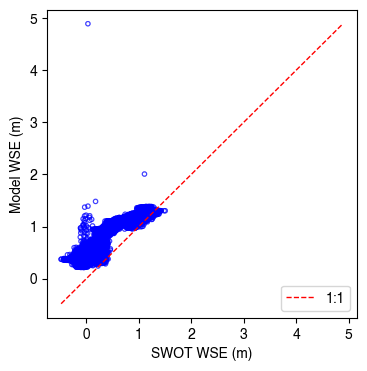

In [53]:
#Scatter plot
plt.figure(figsize=(4, 4))
sp=plt.scatter(swot_wse, model_wse, s=10, alpha=0.5, facecolors='none', edgecolors='blue', linewidths=0.8 )
plt.scatter(swot_wse, model_wse, s=10, alpha=0.5, facecolors='none', edgecolors='blue', linewidths=0.8 )
plt.plot([sm_compare.min().min(), sm_compare.max().max()],
         [sm_compare.min().min(), sm_compare.max().max()],
         'r--', lw=1, label='1:1')
#plt.colorbar(label='Count of pixels')

plt.xlabel('SWOT WSE (m)')
plt.ylabel('Model WSE (m)')
#plt.title('Model (01-01-2021) vs SWOT (04-20-2023)')
plt.legend()
#plt.grid(True)
#plt.tight_layout()
plt.show()


## Making Final Plots for Presentation

Figure saved to /Users/skica/Desktop/2025_Summer_Research/work_folder/swot_model_comparison.jpeg


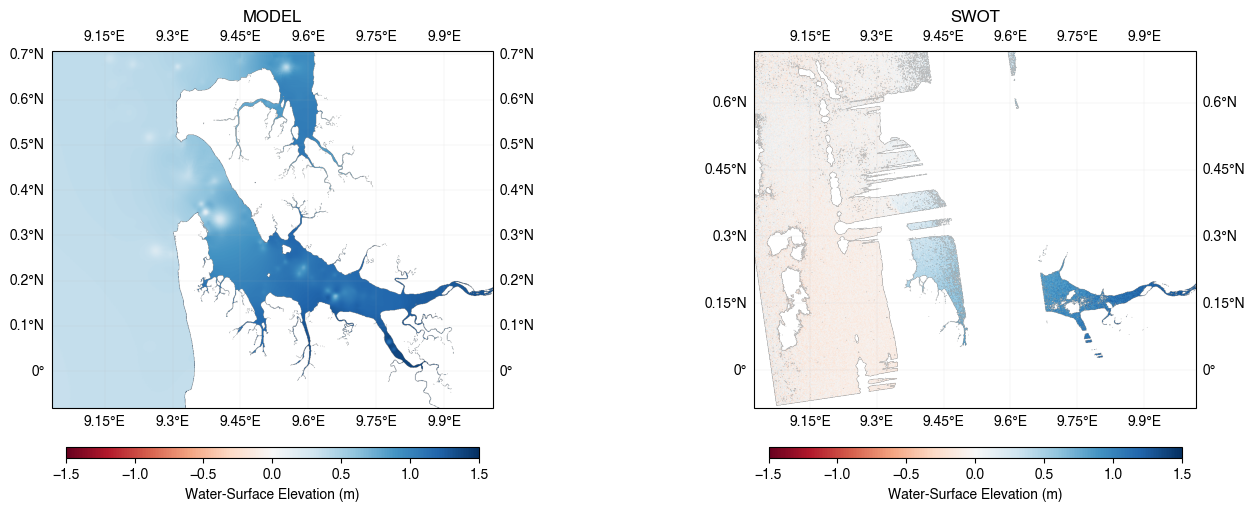

In [54]:
swot_water_latlon  = swot_water.squeeze().rio.reproject("EPSG:4326").squeeze()
model_water_latlon = model_water.squeeze().rio.reproject("EPSG:4326").squeeze()


mpl.rcParams["font.family"] = "Helvetica"
proj = ccrs.PlateCarree()

fig, (ax1, ax2) = plt.subplots(ncols=2,figsize=(14, 5),subplot_kw={"projection": proj},constrained_layout=True)

def plot_raster(ax, da, title):
    da2d = da.squeeze()  # makes sure shape is (ny, nx)
 # Extract the extent (xmin, xmax, ymin, ymax) in lat/lon
    west, south, east, north = da2d.rio.bounds()
    
    img = ax.imshow(da2d.values,extent=(west, east, south, north),origin="upper", transform=proj,cmap="RdBu",vmin=-1.5,vmax=1.5)

    # Gridlines – light grey dashed, no labels (tick labels below)
    ax.gridlines(draw_labels=True, linestyle="-", linewidth=0.2, alpha=0.4,color='.7')

    ax.xaxis.set_major_formatter(LongitudeFormatter())
    ax.yaxis.set_major_formatter(LatitudeFormatter())

    ax.set_title(title)
    
    cbar = fig.colorbar(img, ax=ax, orientation="horizontal", pad=0.05,shrink=0.6,aspect=40,fraction=0.046)
    cbar.set_label("Water‑Surface Elevation (m)")


plot_raster(ax2, swot_water_latlon, "SWOT")
plot_raster(ax1, model_water_latlon, "MODEL")


output = Path("swot_model_comparison.jpeg")
fig.savefig(output, dpi=300, bbox_inches="tight")
print(f"Figure saved to {output.resolve()}")
plt.show()


### Investigating Flat Pixels over OCean

Figure saved to /Users/skica/Desktop/2025_Summer_Research/FINAL_PRESENTATION_FIGURES/diff_map_scatter_rivers.pdf


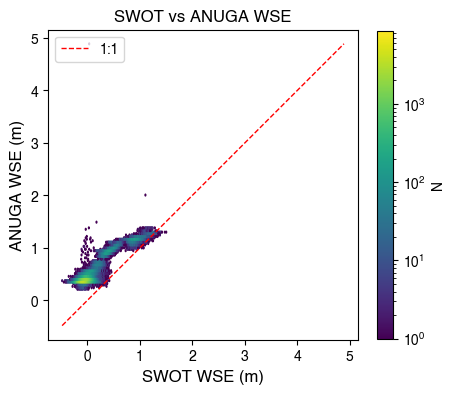

In [65]:
import seaborn as sns
diff_map_viz  = diff_map.squeeze().rio.reproject("EPSG:4326").squeeze()

mpl.rcParams["font.family"] = "Helvetica"
proj = ccrs.PlateCarree()



fig, ax = plt.subplots(figsize=(5, 5))


plt.hexbin(swot_wse, model_wse, gridsize=150, cmap='viridis', bins='log')
# ax.scatter(swot_wse, model_wse, s=10, alpha=0.5, facecolors='none', edgecolors='black', linewidths=0.8)
ax.plot([sm_compare.min().min(), sm_compare.max().max()],
         [sm_compare.min().min(), sm_compare.max().max()],
         'r--', lw=1, label='1:1')
ax.set_aspect('equal', 'box')
Lxlimit = 0.150
Uxlimit = 0.80
Lylimit = 0.395
Uylimit = 0.43

ax2.axhline(y=Lylimit, color='blue', linestyle='--',lw=0.7)
ax2.axhline(y=Uylimit, color='blue', linestyle='--',lw=0.7)
ax2.axvline(x=Lxlimit, color='blue', linestyle='--',lw=0.7)
ax2.axvline(x=Uxlimit, color='blue', linestyle='--',lw=0.7) 
# ax.set_xlim(-.75, 1)
# ax.set_ylim(-.75, 1)

ax.set_xlabel('SWOT WSE (m)',fontsize=12)
ax.set_ylabel('ANUGA WSE (m)',fontsize=12)
ax.set_title('SWOT vs ANUGA WSE',fontsize=12)
plt.colorbar(label='N',shrink=0.8)
plt.legend()
ax.set_box_aspect(1)
#ax2.legend()

# textstr = '\n'.join((r'MAE = %.3f m' % mae, r'Bias = %.3f m' % mb,r'RMSE  = %.3f m' % rmse, r'Corr, R  = %.3f m' % rho,
#                     r'N  = %.0f' % len(swot_wse)))

# # Place text inside ax2
# ax2.text(0.05, 0.95, textstr,transform=ax2.transAxes,fontsize=12,verticalalignment='top',
#          bbox=dict(boxstyle='square,pad=0.3', facecolor='white', alpha=0.7)
# )

# Save
output = Path("/Users/skica/Desktop/2025_Summer_Research/FINAL_PRESENTATION_FIGURES/diff_map_scatter_rivers.pdf")
fig.savefig(output, dpi=300, bbox_inches="tight")
print(f"Figure saved to {output.resolve()}")
plt.show()


In [66]:
# Example if you have an xarray DataArray
swot_da = swot_water_resampled  # your SWOT WSE raster
model_da = model_water # your model WSE raster

# Flatten your WSE data
swot_wse = swot_da.values.flatten()
model_wse = model_da.values.flatten()

# Get coordinate grids
lon2d, lat2d = np.meshgrid(swot_da['x'].values, swot_da['y'].values)
swot_lon = lon2d.flatten()
swot_lat = lat2d.flatten()

In [67]:
flat_model_threshold = ((swot_wse > Lxlimit) & (swot_wse < Uxlimit)) & ((model_wse > Lylimit) & (model_wse < Uylimit))
print(flat_model_threshold.sum())

412


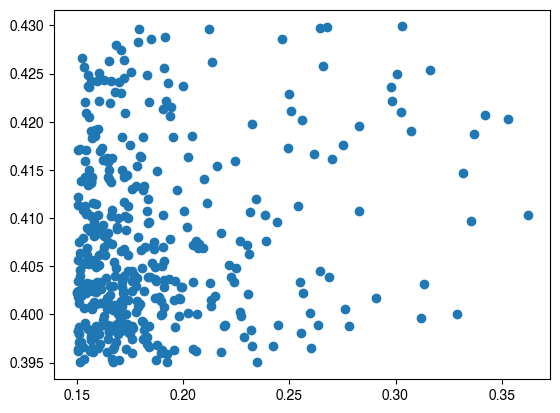

In [68]:
plt.scatter(swot_wse[flat_model_threshold], model_wse[flat_model_threshold])

In [69]:
flat_indices = np.where(flat_model_threshold)[0]


In [70]:
flat_lon = swot_lon[flat_indices]
flat_lat = swot_lat[flat_indices]
xmin, ymin, xmax, ymax = diff_map.rio.bounds()

Text(0, 0.5, 'UTM N')

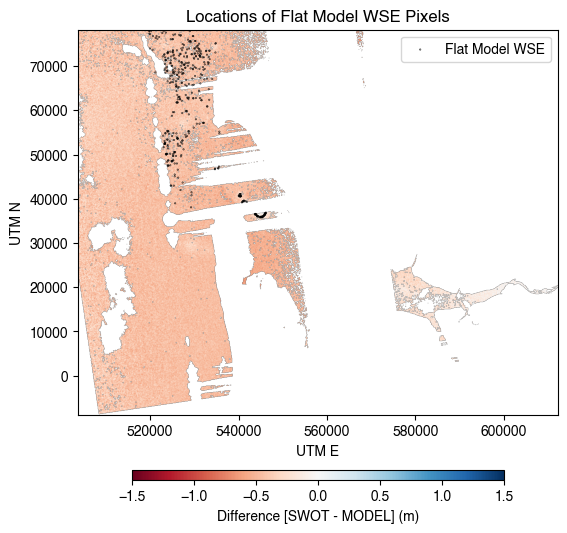

In [71]:
plt.figure(figsize=(8, 6))
plt.imshow(diff_map, extent=[xmin, xmax, ymin, ymax], cmap='RdBu', vmin=-1.5, vmax=1.5)
plt.colorbar(label='Difference [SWOT - MODEL] (m)', orientation="horizontal", pad=0.12,shrink=0.6,aspect=40,fraction=0.046)
plt.scatter(flat_lon, flat_lat, facecolors='none', edgecolors='black', s=0.2, label='Flat Model WSE', alpha=0.8)
plt.legend()
plt.title("Locations of Flat Model WSE Pixels")
#plt.colorbar(label='Difference [SWOT - MODEL] (m)', orientation="horizontal", pad=0.1,shrink=0.6,aspect=40,fraction=0.046)
plt.xlabel("UTM E")
plt.ylabel("UTM N")


In [72]:
# mask = np.full_like(diff_map, np.nan)
# mask[flat_indices] = diff_map[flat_indices]
# plt.imshow(mask, cmap='coolwarm')

Text(0, 0.5, 'Latitude')

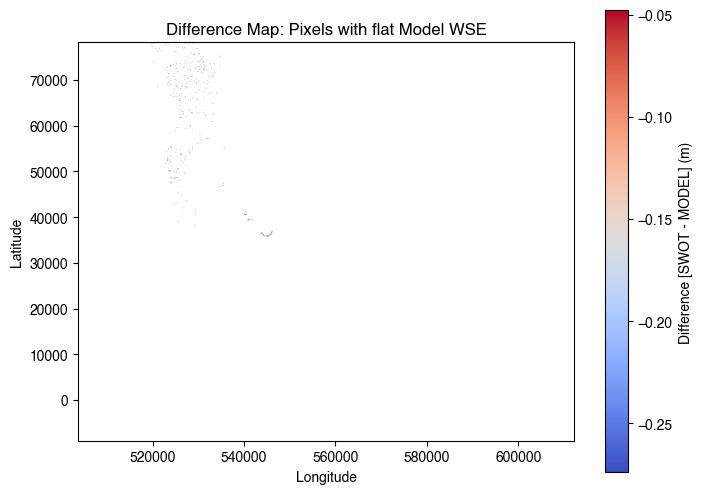

In [73]:
# Step 1: Flatten the diff_map (but keep shape for later reshape)
diff_flat = diff_map.values.flatten()

# Step 2: Create an empty array to hold masked results
masked_flat = np.full_like(diff_flat, np.nan)

# Step 3: Assign values only at flat indices
masked_flat[flat_indices] = diff_flat[flat_indices]

# Step 4: Reshape back to 2D shape of diff_map for plotting
masked_2d = masked_flat.reshape(diff_map.shape)

# Step 5: Plot
plt.figure(figsize=(8, 6))
xmin, ymin, xmax, ymax = diff_map.rio.bounds()
plt.imshow(masked_2d, extent=[xmin, xmax, ymin, ymax], cmap='coolwarm')
#plt.plot(model_water)
plt.title("Difference Map: Pixels with flat Model WSE")
plt.colorbar(label='Difference [SWOT - MODEL] (m)')
plt.xlabel("Longitude")
plt.ylabel("Latitude")


Figure saved to /Users/skica/Desktop/2025_Summer_Research/FINAL_PRESENTATION_FIGURES/flat_pixels.pdf


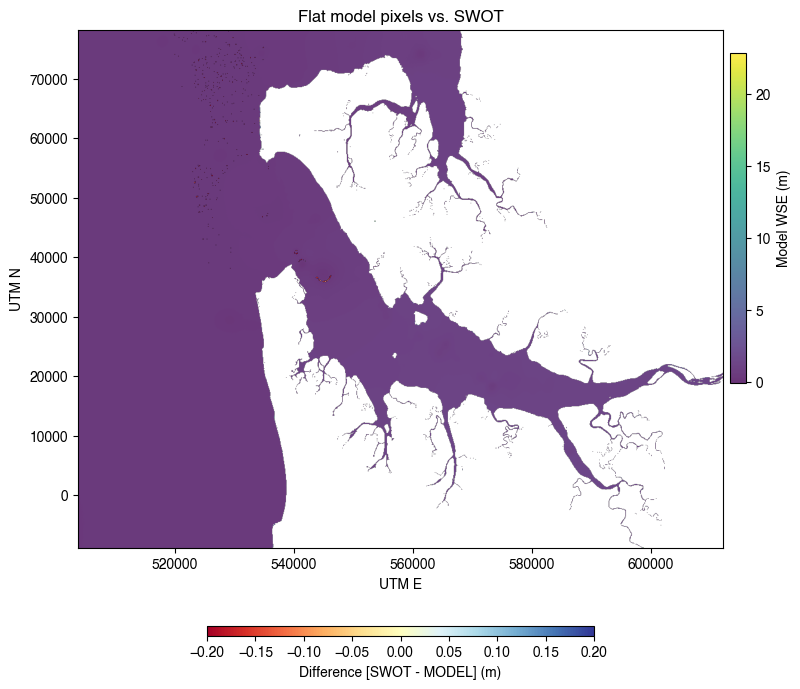

In [74]:
#fig, ax = plt.subplots(figsize=(8, 6))
fig = plt.figure(figsize=(14, 8),constrained_layout=True)
gs = gridspec.GridSpec(ncols=3, nrows=1, figure=fig, width_ratios=[1.8, 0.2, 1.5])

proj = ccrs.PlateCarree()
ax1 = fig.add_subplot(gs[0])
# ax2 = fig.add_subplot(gs[2])                   

# 1. Background greyscale: Model WSE
img1 = ax1.imshow(model_water_latlon.values,extent=[xmin, xmax, ymin, ymax],cmap='viridis', alpha=0.8, origin='upper')

# 2. Overlay: masked flat WSE pixels (SWOT - MODEL difference)
img2 = ax1.imshow(masked_2d,extent=[xmin, xmax, ymin, ymax],cmap='RdYlBu', origin='upper',vmin=-0.2,vmax=0.2)

# 3. Colorbar for model water (left or top)
cbar1 = fig.colorbar(img1, ax=ax1, orientation="vertical",shrink=0.5, pad=0.01, aspect=20)
cbar1.set_label("Model WSE (m)")

# 4. Colorbar for difference map (bottom)
cbar2 = fig.colorbar(img2, ax=ax1, orientation="horizontal",pad=0.05, shrink=0.6, aspect=40, fraction=0.046)
cbar2.set_label("Difference [SWOT - MODEL] (m)")

# 5. Title and axis labels
ax1.set_title("Flat model pixels vs. SWOT")
ax1.set_xlabel("UTM E")
ax1.set_ylabel("UTM N")

# ax2.scatter(swot_wse[flat_model_threshold], model_wse[flat_model_threshold], s=15, alpha=0.9, facecolors='none', edgecolors='black', linewidths=0.8)
# ax2.set_xlabel('SWOT WSE (m)',fontsize=12)
# ax2.set_ylabel('Model WSE (m)',fontsize=12)
# ax2.set_title('SWOT vs Model WSE',fontsize=12)

output = Path("/Users/skica/Desktop/2025_Summer_Research/FINAL_PRESENTATION_FIGURES/flat_pixels.pdf")
fig.savefig(output, dpi=300, bbox_inches="tight")
print(f"Figure saved to {output.resolve()}")

plt.show()
